# Manual Feature Selection for Car-Price Regression

This notebook uses train-only missingness, variance, redundancy, and domain interpretation to define a compact feature set. It then compares the selected set with a broader baseline on the same untouched holdout.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.metrics import mean_absolute_error, root_mean_squared_error
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.model_selection import train_test_split

RANDOM_SEED = 21
OUTPUT_DIR = Path('generated/feature-selection-021')
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
relative_path = Path('data/car_prices/cars.csv')
data_path = next(
    candidate / relative_path
    for candidate in (Path.cwd(), *Path.cwd().parents)
    if (candidate / relative_path).exists()
)
cars = pd.read_csv(data_path).drop_duplicates()
cars = cars.loc[cars['price_usd'].gt(0)].copy()
cars['vehicle_age'] = 2019 - cars['year_produced']
cars = cars.loc[cars['vehicle_age'].between(0, 80)].copy()
train, test = train_test_split(cars, test_size=0.25, random_state=RANDOM_SEED)
print(f'train rows: {len(train):,}; holdout rows: {len(test):,}')

train rows: 28,868; holdout rows: 9,623


## 1. Inspect Training Features

Selection rules are calculated on training rows only. We inspect missingness, near-constant Boolean columns, and correlation among numeric candidates before specifying the compact set.

In [2]:
candidate_numeric = [
    'odometer_value', 'vehicle_age', 'engine_capacity',
    'number_of_photos', 'up_counter', 'duration_listed',
]
candidate_categorical = [
    'manufacturer_name', 'transmission', 'engine_fuel',
    'body_type', 'drivetrain', 'state', 'has_warranty', 'is_exchangeable',
]
candidate_features = candidate_numeric + candidate_categorical
missingness = train[candidate_features].isna().mean().sort_values(ascending=False)
numeric_correlation = train[candidate_numeric].corr(numeric_only=True)
boolean_prevalence = train[['has_warranty', 'is_exchangeable']].mean().sort_values()
print('largest missing shares:')
print(missingness.head().round(3).to_string())
print()
print('boolean prevalence:')
print(boolean_prevalence.round(3).to_string())

largest missing shares:
engine_capacity     0.0
odometer_value      0.0
vehicle_age         0.0
number_of_photos    0.0
up_counter          0.0

boolean prevalence:
has_warranty       0.011
is_exchangeable    0.350


## 2. Define Full and Selected Pipelines

The selected set removes fields that add complexity without improving this teaching comparison. Both models use identical preprocessing and random-forest settings.

In [3]:
selected_numeric = ['odometer_value', 'vehicle_age', 'engine_capacity', 'duration_listed']
selected_categorical = ['manufacturer_name', 'transmission', 'body_type', 'drivetrain']

def make_pipeline(numeric_features, categorical_features):
    preprocessing = ColumnTransformer([
        ('numeric', SimpleImputer(strategy='median'), numeric_features),
        ('categorical', Pipeline([
            ('imputer', SimpleImputer(strategy='most_frequent')),
            ('onehot', OneHotEncoder(handle_unknown='ignore', min_frequency=20)),
        ]), categorical_features),
    ])
    return Pipeline([
        ('preprocessing', preprocessing),
        ('model', RandomForestRegressor(
            n_estimators=160,
            min_samples_leaf=3,
            random_state=RANDOM_SEED,
            n_jobs=-1,
        )),
    ])

full_model = make_pipeline(candidate_numeric, candidate_categorical)
selected_model = make_pipeline(selected_numeric, selected_categorical)

## 3. Compare on One Untouched Holdout

In [4]:
target_train = np.log1p(train['price_usd'])
target_test = np.log1p(test['price_usd'])
models = {
    'Full candidate set': (full_model, candidate_features),
    'Selected feature set': (selected_model, selected_numeric + selected_categorical),
}
rows = []
for name, (model, columns) in models.items():
    model.fit(train[columns], target_train)
    prediction = model.predict(test[columns])
    rows.append({
        'model': name,
        'RMSE': root_mean_squared_error(target_test, prediction),
        'MAE': mean_absolute_error(target_test, prediction),
        'features': len(columns),
    })

baseline = DummyRegressor(strategy='mean').fit(np.zeros((len(train), 1)), target_train)
baseline_prediction = baseline.predict(np.zeros((len(test), 1)))
rows.append({
    'model': 'Mean baseline',
    'RMSE': root_mean_squared_error(target_test, baseline_prediction),
    'MAE': mean_absolute_error(target_test, baseline_prediction),
    'features': 0,
})
metrics = pd.DataFrame(rows).set_index('model')
print(metrics.round(3).to_string())
assert metrics.loc['Selected feature set', 'RMSE'] < metrics.loc['Mean baseline', 'RMSE']

                       RMSE    MAE  features
model                                       
Full candidate set    0.335  0.227        14
Selected feature set  0.351  0.237         8
Mean baseline         1.020  0.822         0


## 4. Visualize Selection Evidence and Results

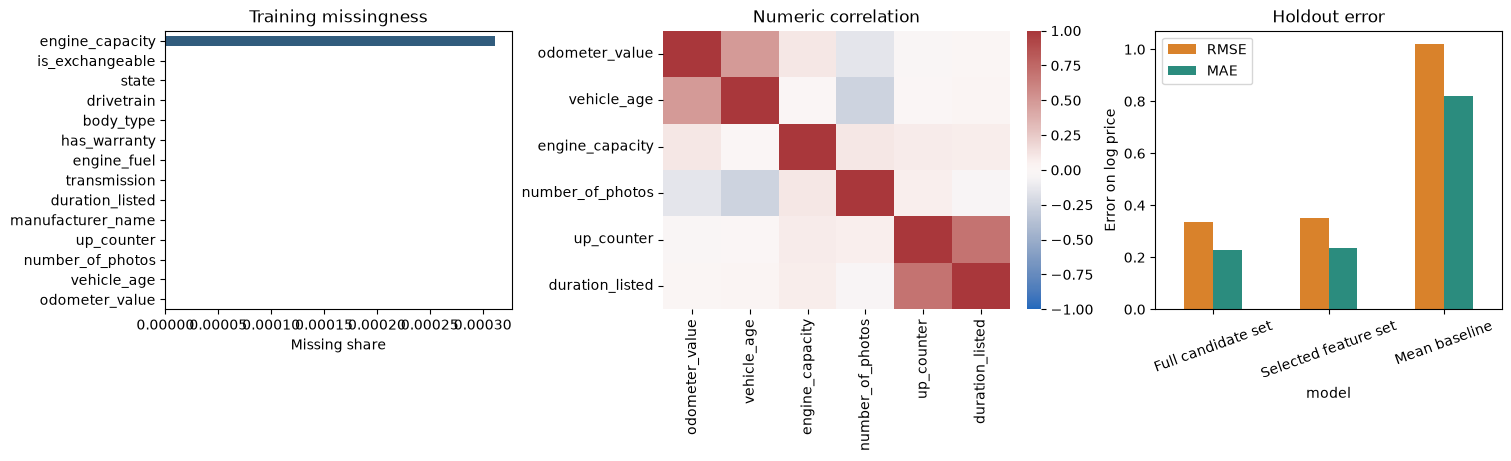

saved: generated\feature-selection-021\manual-feature-selection.png


In [5]:
figure, axes = plt.subplots(1, 3, figsize=(15, 4.5), constrained_layout=True)
missingness.sort_values().plot.barh(color='#315c7d', ax=axes[0])
axes[0].set(title='Training missingness', xlabel='Missing share')
sns.heatmap(numeric_correlation, cmap='vlag', center=0, vmin=-1, vmax=1, ax=axes[1])
axes[1].set_title('Numeric correlation')
metrics[['RMSE', 'MAE']].plot.bar(color=['#d9822b', '#2b8c7e'], ax=axes[2])
axes[2].set(title='Holdout error', ylabel='Error on log price')
axes[2].tick_params(axis='x', rotation=20)
figure_path = OUTPUT_DIR / 'manual-feature-selection.png'
figure.savefig(figure_path, dpi=170, bbox_inches='tight')
plt.show()
print(f'saved: {figure_path}')